<div align="center">

# Assignment 12 — Markov Models & Stochastic Processes

---

**Name:** Shreyas Sovani &nbsp;|&nbsp; **Roll No:** 22 &nbsp;|&nbsp; **Class:** AIML-F &nbsp;|&nbsp; **Subject:** Machine Learning

---

</div>


# Assignment 12 — Markov Models & Stochastic Processes

*Probabilistic Modeling: Discrete-Time Markov Chains (DTMC), Chapman-Kolmogorov Equations, and Stationary Distributions*

**Data:** A 3-state weather Markov chain (Sunny / Cloudy / Rainy), sequences simulated from it, and a small 6-page web graph for PageRank.

**Objective:** Build and simulate a DTMC, compute $n$-step transition probabilities and verify the Chapman–Kolmogorov equations, find the stationary distribution in four independent ways, estimate a transition matrix from observed data, and apply stationary distributions to rank web pages.

## 1. Theory

A **stochastic process** $\{X_0, X_1, X_2, \dots\}$ is a sequence of random variables indexed by time. A **discrete-time Markov chain (DTMC)** on a finite state space $S = \{1, \dots, m\}$ has the **Markov property** — the future depends only on the present state, not on how we got there:

$$P(X_{n+1} = j \mid X_n = i, X_{n-1}, \dots, X_0) = P(X_{n+1} = j \mid X_n = i) = p_{ij}$$

The chain is fully described by its **transition matrix** $P = [p_{ij}]$; every row is a probability distribution ($p_{ij} \ge 0$, $\sum_j p_{ij} = 1$).

**$n$-step transitions & the Chapman–Kolmogorov equations.** To go from $i$ to $j$ in $m + n$ steps, the chain must pass through *some* state $k$ after $m$ steps:

$$p^{(m+n)}_{ij} = \sum_{k \in S} p^{(m)}_{ik} \, p^{(n)}_{kj} \qquad\Longleftrightarrow\qquad P^{(m+n)} = P^{(m)} P^{(n)}$$

Applying this repeatedly gives $P^{(n)} = P^n$. If $\boldsymbol{\pi}^{(0)}$ is the starting distribution (a row vector), the distribution after $n$ steps is $\boldsymbol{\pi}^{(n)} = \boldsymbol{\pi}^{(0)} P^n$.

**Stationary distribution.** A distribution the chain leaves unchanged:

$$\boldsymbol{\pi} = \boldsymbol{\pi} P, \qquad \sum_i \pi_i = 1, \quad \pi_i \ge 0$$

So $\boldsymbol{\pi}$ is a left eigenvector of $P$ with eigenvalue 1. If the chain is **irreducible** (every state can reach every other) and **aperiodic** (no forced cycles), then $\boldsymbol{\pi}$ is unique, $\boldsymbol{\pi}^{(n)} \to \boldsymbol{\pi}$ from *any* start, $\pi_i$ is the long-run fraction of time spent in state $i$, and the mean time to return to $i$ is $1 / \pi_i$.

**Estimating $P$ from data.** Given an observed sequence with $n_{ij}$ transitions from $i$ to $j$, the maximum-likelihood estimate is $\hat{p}_{ij} = n_{ij} / \sum_k n_{ik}$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Circle, FancyArrowPatch

sns.set_theme(style='whitegrid')
%matplotlib inline

---
# Part A — A Weather Markov Chain

Tomorrow's weather depends only on today's: a sunny day is usually followed by another sunny day, rain tends to persist, and cloudy days can go either way.

In [2]:
states = ['Sunny', 'Cloudy', 'Rainy']
P = np.array([[0.7, 0.2, 0.1],
              [0.3, 0.4, 0.3],
              [0.2, 0.4, 0.4]])

print('Every row sums to 1:', np.allclose(P.sum(axis=1), 1))
pd.DataFrame(P, index=[f'from {s}' for s in states],
             columns=[f'to {s}' for s in states])

Every row sums to 1: True


,to Sunny,to Cloudy,to Rainy
from Sunny,0.7,0.2,0.1
from Cloudy,0.3,0.4,0.3
from Rainy,0.2,0.4,0.4


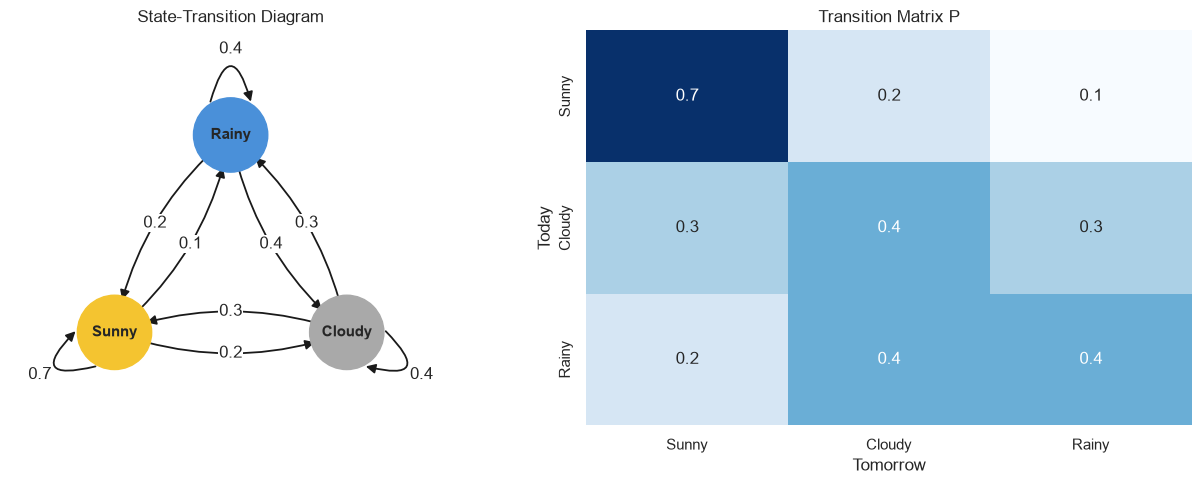

In [3]:
def draw_chain(P, names, ax, colors=('#f4c430', '#a9a9a9', '#4a90d9')):
    """State-transition diagram: nodes on a triangle, arrows labelled p_ij."""
    pos = np.array([[0.0, 0.0], [2.0, 0.0], [1.0, 1.7]])
    centre, r = pos.mean(axis=0), 0.32
    for i, (x, y) in enumerate(pos):
        ax.add_patch(Circle((x, y), r, color=colors[i], zorder=3))
        ax.text(x, y, names[i], ha='center', va='center', zorder=4,
                fontsize=11, fontweight='bold')
        # self-loop on the outer side of the node
        out = (pos[i] - centre) / np.linalg.norm(pos[i] - centre)
        rot = lambda v, a: np.array([v[0] * np.cos(a) - v[1] * np.sin(a),
                                     v[0] * np.sin(a) + v[1] * np.cos(a)])
        a, b = pos[i] + r * rot(out, 0.6), pos[i] + r * rot(out, -0.6)
        ax.add_patch(FancyArrowPatch(a, b, connectionstyle='arc3,rad=-1.8',
                                     arrowstyle='-|>', mutation_scale=14,
                                     lw=1.3, color='k'))
        lx, ly = pos[i] + out * (r + 0.42)
        ax.text(lx, ly, f'{P[i, i]:.1f}', ha='center', va='center')
    for i in range(len(P)):
        for j in range(len(P)):
            if i == j or P[i, j] == 0:
                continue
            ax.add_patch(FancyArrowPatch(pos[i], pos[j],
                                         connectionstyle='arc3,rad=0.18',
                                         arrowstyle='-|>', mutation_scale=14,
                                         shrinkA=24, shrinkB=24, lw=1.3,
                                         color='k'))
            d = pos[j] - pos[i]
            lx, ly = (pos[i] + pos[j]) / 2 + 0.09 * np.array([d[1], -d[0]])
            ax.text(lx, ly, f'{P[i, j]:.1f}', ha='center', va='center',
                    bbox=dict(facecolor='white', edgecolor='none', pad=1))
    ax.set_xlim(-0.9, 2.9)
    ax.set_ylim(-0.8, 2.6)
    ax.set_aspect('equal')
    ax.axis('off')


fig, axes = plt.subplots(1, 2, figsize=(13, 5))
draw_chain(P, states, axes[0])
axes[0].set_title('State-Transition Diagram')
sns.heatmap(P, annot=True, fmt='.1f', cmap='Blues', cbar=False,
            xticklabels=states, yticklabels=states, ax=axes[1])
axes[1].set_xlabel('Tomorrow')
axes[1].set_ylabel('Today')
axes[1].set_title('Transition Matrix P')
plt.tight_layout()
plt.show()

## Simulating the Chain

Each next state is drawn from the row of $P$ for the current state — the past beyond today is never used.

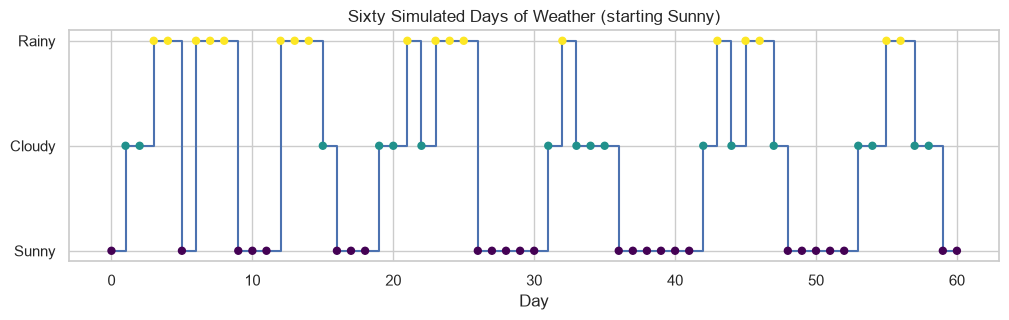

In [4]:
def simulate(P, starts, n_steps, rng):
    """Simulate one path per start state; returns (n_paths, n_steps + 1)."""
    cum = P.cumsum(axis=1)
    cum[:, -1] = 1.0
    paths = np.empty((len(starts), n_steps + 1), dtype=int)
    paths[:, 0] = starts
    for t in range(n_steps):
        u = rng.random(len(starts))
        paths[:, t + 1] = (u[:, None] > cum[paths[:, t]]).sum(axis=1)
    return paths


rng = np.random.default_rng(42)
days = simulate(P, [0], 60, rng)[0]

plt.figure(figsize=(12, 3))
plt.step(range(len(days)), days, where='post')
plt.scatter(range(len(days)), days, c=days, cmap='viridis', zorder=3, s=25)
plt.yticks(range(3), states)
plt.xlabel('Day')
plt.title('Sixty Simulated Days of Weather (starting Sunny)')
plt.show()

## $n$-Step Transitions & Chapman–Kolmogorov

In [5]:
P2 = P @ P
P3 = np.linalg.matrix_power(P, 3)

print('Two-step matrix P^(2) = P P:')
print(pd.DataFrame(P2, index=states, columns=states).round(3))
print(f'\nP(Rainy in 3 days | Sunny today) = p^(3)[Sunny, Rainy] = '
      f'{P3[0, 2]:.4f}')

Two-step matrix P^(2) = P P:
        Sunny  Cloudy  Rainy
Sunny    0.57    0.26   0.17
Cloudy   0.39    0.34   0.27
Rainy    0.34    0.36   0.30

P(Rainy in 3 days | Sunny today) = p^(3)[Sunny, Rainy] = 0.2030


In [6]:
m, n = 2, 3
Pm, Pn = np.linalg.matrix_power(P, m), np.linalg.matrix_power(P, n)
P_mn = np.linalg.matrix_power(P, m + n)
print(f'Matrix form:  P^({m + n}) == P^({m}) P^({n}) ->',
      np.allclose(P_mn, Pm @ Pn))

# one entry written out as a sum over the intermediate state k
i, j = 0, 2
terms = [Pm[i, k] * Pn[k, j] for k in range(3)]
print('\nElement form for Sunny -> Rainy (sum over intermediate state k):')
for k, t in enumerate(terms):
    print(f'   via {states[k]:<6}: {Pm[i, k]:.4f} x {Pn[k, j]:.4f} = {t:.4f}')
print(f'   sum = {sum(terms):.4f}   vs   P^5 entry = {P_mn[i, j]:.4f}')

Matrix form:  P^(5) == P^(2) P^(3) -> True

Element form for Sunny -> Rainy (sum over intermediate state k):
   via Sunny : 0.5700 x 0.2030 = 0.1157
   via Cloudy: 0.2600 x 0.2490 = 0.0647
   via Rainy : 0.1700 x 0.2620 = 0.0445
   sum = 0.2250   vs   P^5 entry = 0.2250


In [7]:
# Monte Carlo check: run 100,000 independent 3-day paths from Sunny
paths = simulate(P, np.zeros(100_000, dtype=int), 3, rng)
freq = np.bincount(paths[:, -1], minlength=3) / len(paths)

pd.DataFrame({'Simulated': freq, 'Exact p^(3)[Sunny, j]': P3[0]},
             index=states).round(4)

,Simulated,"Exact p^(3)[Sunny, j]"
Sunny,0.5083,0.511
Cloudy,0.2877,0.286
Rainy,0.2040,0.203


The matrix power, the explicit sum over intermediate states and brute-force simulation all agree.

## Convergence to Equilibrium

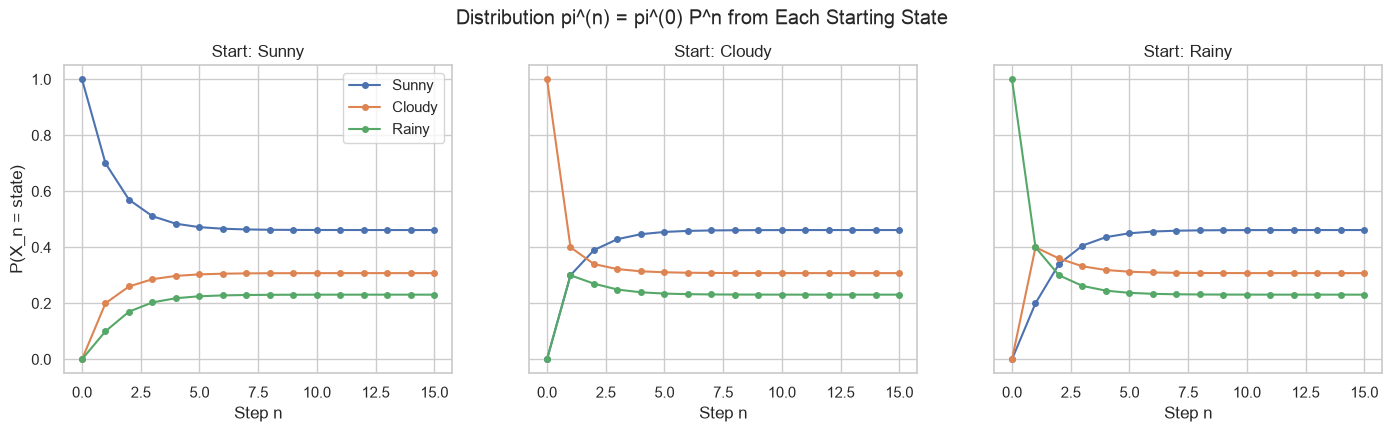

In [8]:
steps = 15
fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharey=True)
for s, ax in enumerate(axes):
    pi_n = np.zeros((steps + 1, 3))
    pi_n[0, s] = 1.0                          # start surely in state s
    for t in range(steps):
        pi_n[t + 1] = pi_n[t] @ P             # pi^(t+1) = pi^(t) P
    for j in range(3):
        ax.plot(pi_n[:, j], 'o-', markersize=4, label=states[j])
    ax.set_title(f'Start: {states[s]}')
    ax.set_xlabel('Step n')
axes[0].set_ylabel('P(X_n = state)')
axes[0].legend()
plt.suptitle('Distribution pi^(n) = pi^(0) P^n from Each Starting State',
             y=1.02)
plt.show()

In [9]:
for k in [1, 2, 5, 10, 20]:
    print(f'P^{k}:')
    print(np.linalg.matrix_power(P, k).round(4), '\n')

P^1:
[[0.7 0.2 0.1]
 [0.3 0.4 0.3]
 [0.2 0.4 0.4]] 

P^2:
[[0.57 0.26 0.17]
 [0.39 0.34 0.27]
 [0.34 0.36 0.3 ]] 

P^5:
[[0.4718 0.3032 0.225 ]
 [0.4548 0.3107 0.2346]
 [0.45   0.3128 0.2373]] 

P^10:
[[0.4617 0.3076 0.2307]
 [0.4614 0.3078 0.2308]
 [0.4613 0.3078 0.2309]] 

P^20:
[[0.4615 0.3077 0.2308]
 [0.4615 0.3077 0.2308]
 [0.4615 0.3077 0.2308]] 



Whatever the starting weather, the distribution settles to the same values within about 10 steps, and the rows of $P^n$ become identical — the chain "forgets" where it started.

## Stationary Distribution — Four Ways

In [10]:
# 1. Left eigenvector of P for eigenvalue 1 (= right eigenvector of P^T)
eig_vals, eig_vecs = np.linalg.eig(P.T)
k = np.argmin(np.abs(eig_vals - 1))
pi_eig = np.real(eig_vecs[:, k])
pi_eig = pi_eig / pi_eig.sum()

# 2. Linear system: pi (P - I) = 0 together with sum(pi) = 1
A = np.vstack([(P - np.eye(3)).T, np.ones(3)])
b = np.r_[np.zeros(3), 1.0]
pi_lin = np.linalg.lstsq(A, b, rcond=None)[0]

# 3. Power method: any row of P^n for large n
pi_pow = np.linalg.matrix_power(P, 100)[0]

# 4. Long-run fraction of time in a 100,000-day simulation
long_path = simulate(P, [0], 100_000, rng)[0]
pi_sim = np.bincount(long_path, minlength=3) / len(long_path)

stationary = pd.DataFrame({'Eigenvector': pi_eig, 'Linear system': pi_lin,
                           'Power method': pi_pow, 'Simulation': pi_sim},
                          index=states)
print('Eigenvalues of P:', np.round(np.sort(np.real(eig_vals))[::-1], 4))
print('pi P == pi      :', np.allclose(pi_eig @ P, pi_eig))
stationary.round(4)

Eigenvalues of P: [1.     0.4562 0.0438]
pi P == pi      : True


,Eigenvector,Linear system,Power method,Simulation
Sunny,0.4615,0.4615,0.4615,0.4676
Cloudy,0.3077,0.3077,0.3077,0.3031
Rainy,0.2308,0.2308,0.2308,0.2292


In [11]:
# Mean recurrence time: average gap between successive visits to a state
rows = []
for s, name in enumerate(states):
    visits = np.flatnonzero(long_path == s)
    rows.append({'State': name, 'pi': pi_eig[s],
                 'Theory 1/pi (days)': 1 / pi_eig[s],
                 'Simulated mean return time': np.diff(visits).mean()})
pd.DataFrame(rows).set_index('State').round(3)

,pi,Theory 1/pi (days),Simulated mean return time
State,,,
Sunny,0.462,2.167,2.138
Cloudy,0.308,3.250,3.299
Rainy,0.231,4.333,4.362


In the long run it is sunny about 46% of the time; a sunny day comes back every ~2.2 days on average, rain only every ~4.3 days. The second-largest eigenvalue ($\approx 0.46$) controls how fast $P^n$ converges: the gap to equilibrium shrinks roughly like $0.46^n$, so after 10 steps it is below 1%.

## When the Limit Does Not Exist: a Periodic Chain

A stationary distribution can exist even when $\boldsymbol{\pi}^{(n)}$ never converges. In this 2-state chain the walker always switches state, so the chain has **period 2**:

In [12]:
P_per = np.array([[0.0, 1.0],
                  [1.0, 0.0]])
pi0 = np.array([1.0, 0.0])

for k in range(1, 5):
    print(f'n = {k}:  pi^(n) = {pi0 @ np.linalg.matrix_power(P_per, k)}')
print('\n[0.5, 0.5] is stationary:',
      np.allclose(np.array([0.5, 0.5]) @ P_per, [0.5, 0.5]))

n = 1:  pi^(n) = [0. 1.]
n = 2:  pi^(n) = [1. 0.]
n = 3:  pi^(n) = [0. 1.]
n = 4:  pi^(n) = [1. 0.]

[0.5, 0.5] is stationary: True


$\boldsymbol{\pi} = (0.5, 0.5)$ satisfies $\boldsymbol{\pi} = \boldsymbol{\pi} P$, but starting from state 0 the distribution flips forever between $(1, 0)$ and $(0, 1)$. Aperiodicity is exactly what the weather chain has (each state can stay put), and why it converges.

---
# Part B — Estimating a Markov Chain from Observed Data

In practice $P$ is unknown and must be learned from an observed sequence. We pretend the 100,000-day simulation is real data and estimate $P$ by counting transitions.

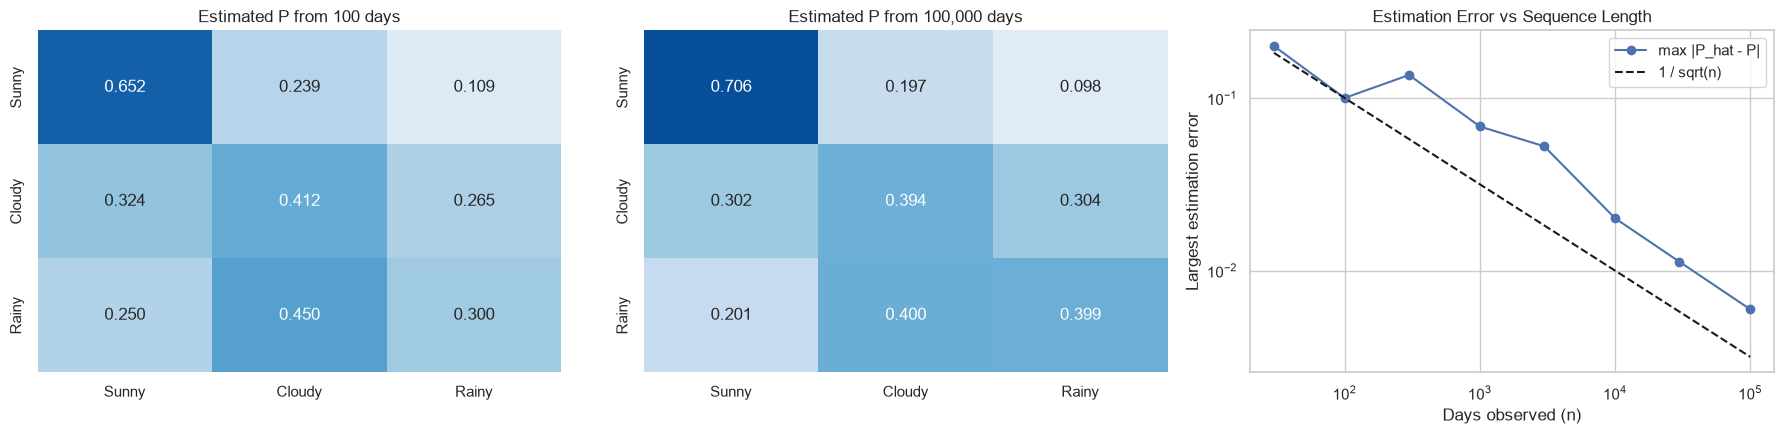

In [13]:
def estimate_P(path, m):
    """Maximum-likelihood estimate: transition counts, row-normalised."""
    counts = np.zeros((m, m))
    np.add.at(counts, (path[:-1], path[1:]), 1)
    return counts / counts.sum(axis=1, keepdims=True)


lengths = [30, 100, 300, 1_000, 3_000, 10_000, 30_000, 100_000]
errors = [np.abs(estimate_P(long_path[:n + 1], 3) - P).max() for n in lengths]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, n in zip(axes[:2], [100, 100_000]):
    sns.heatmap(estimate_P(long_path[:n + 1], 3), annot=True, fmt='.3f',
                cmap='Blues', cbar=False, vmin=0, vmax=0.8,
                xticklabels=states, yticklabels=states, ax=ax)
    ax.set_title(f'Estimated P from {n:,} days')
axes[2].loglog(lengths, errors, 'o-', label='max |P_hat - P|')
axes[2].loglog(lengths, 1 / np.sqrt(lengths), 'k--', label='1 / sqrt(n)')
axes[2].set_xlabel('Days observed (n)')
axes[2].set_ylabel('Largest estimation error')
axes[2].set_title('Estimation Error vs Sequence Length')
axes[2].legend()
plt.tight_layout()
plt.show()

With 100 days the estimates are off by up to ~0.1; with 100,000 days they match the true $P$ to two decimals. The error shrinks like $1/\sqrt{n}$ — the usual Monte Carlo rate.

---
# Part C — Application: PageRank as a Stationary Distribution

Google's PageRank models a "random surfer" who follows a random link on the current page with probability $d = 0.85$, and otherwise jumps to any page uniformly at random. That is a Markov chain over pages,

$$G = d\,S + \frac{1 - d}{N}\,\mathbf{1}\mathbf{1}^\top,$$

where $S$ is the link-following matrix. The random jump makes $G$ irreducible and aperiodic, so it has a unique stationary distribution — the **PageRank** of each page.

In [14]:
links = {'A': ['B', 'C'], 'B': ['C'], 'C': ['A'],
         'D': ['C'], 'E': ['A', 'D', 'F'], 'F': ['C', 'E']}
pages = list(links)
N, d = len(pages), 0.85

S = np.zeros((N, N))
for src, outs in links.items():
    for dst in outs:
        S[pages.index(src), pages.index(dst)] = 1 / len(outs)
G = d * S + (1 - d) / N

# power iteration: pi <- pi G until it stops changing
pi = np.full(N, 1 / N)
for it in range(1, 1000):
    new = pi @ G
    if np.abs(new - pi).sum() < 1e-12:
        break
    pi = new

w, v = np.linalg.eig(G.T)
pi_check = np.real(v[:, np.argmin(np.abs(w - 1))])
pi_check = pi_check / pi_check.sum()

print(f'Power iteration converged in {it} iterations')
print('Matches eigenvector solution:', np.allclose(pi, pi_check))
ranks = pd.Series(pi, index=pages).sort_values(ascending=False)
ranks.round(4)

Power iteration converged in 55 iterations
Matches eigenvector solution: True


C    0.3661
A    0.3477
B    0.1728
E    0.0405
D    0.0365
F    0.0365
dtype: float64

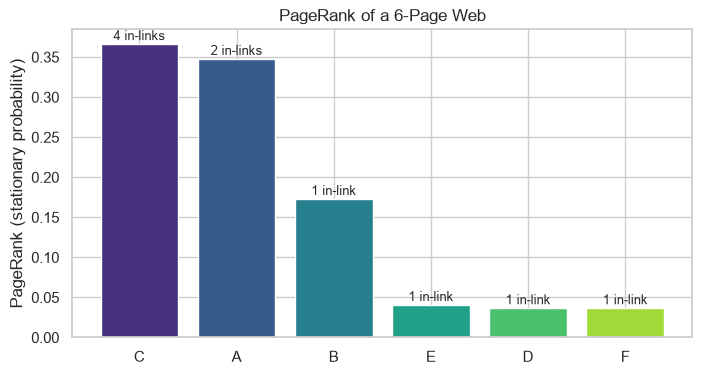

In [15]:
in_links = {p: sum(p in outs for outs in links.values()) for p in pages}

plt.figure(figsize=(8, 4))
plt.bar(ranks.index, ranks.values,
        color=sns.color_palette('viridis', N))
for x, (p, val) in enumerate(ranks.items()):
    label = f"{in_links[p]} in-link{'s' if in_links[p] != 1 else ''}"
    plt.text(x, val + 0.005, label, ha='center', fontsize=9)
plt.ylabel('PageRank (stationary probability)')
plt.title('PageRank of a 6-Page Web')
plt.show()

Page C ranks highest — four pages link to it — and A comes second with only two in-links, because one of them comes from the top-ranked C, which gives A its whole vote. Importance flows through the chain: a link from an important page is worth more than a link from an obscure one.

## Conclusion

- **DTMC:** the weather chain is fully specified by a $3 \times 3$ row-stochastic matrix; simulation needs only the current state, illustrating the Markov property.
- **Chapman–Kolmogorov:** $P^{(5)} = P^{(2)}P^{(3)}$ holds exactly, the explicit sum over intermediate states reproduces each entry, and 100,000 simulated 3-day paths match $P^3$ to about two decimal places.
- **Stationary distribution:** eigenvector, linear system, power method and long-run simulation all give $\boldsymbol{\pi} \approx$ (0.46, 0.31, 0.23) for Sunny/Cloudy/Rainy; mean return times match $1/\pi_i$. Convergence takes ~10 steps from any start because the second eigenvalue is only $\approx 0.46$. A periodic chain shows that a stationary distribution need not be a limit.
- **Learning from data:** counting transitions recovers $P$, with error shrinking like $1/\sqrt{n}$.
- **PageRank** is the stationary distribution of a "random surfer" chain — the same $\boldsymbol{\pi} = \boldsymbol{\pi} G$ computation ranks pages by how much probability flows into them.
- Limitations: the Markov property is a strong assumption (real weather depends on more than yesterday), and $P$ needs plenty of data for rarely visited states. Hidden Markov Models extend the idea to states that cannot be observed directly.